In [1]:
import os
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib import colors as mcolors
from datetime import datetime, timedelta


In [2]:
# colormap definition with white in the middle
n=39
x = 0.5
lower = plt.cm.seismic_r(np.linspace(0, x, n))
# white = plt.cm.seismic_r(np.ones(80-2*n)*x)
upper = plt.cm.seismic_r(np.linspace(1-x, 1, n))
colors = np.vstack((lower, upper))
# colors = np.vstack((lower, white, upper))

from matplotlib.colors import LinearSegmentedColormap
tmap = LinearSegmentedColormap.from_list('map_white', colors)
# tmap = matplotlib.colors.LinearSegmentedColormap.from_list('map_white', colors)

plt.rcParams.update({
'font.size': 20,           # Default text size
'axes.titlesize': 16,      # Title size
'axes.labelsize': 16,      # Axis label size
'xtick.labelsize': 16,     # X-axis tick label size
'ytick.labelsize': 16,     # Y-axis tick label size
'legend.fontsize': 16,     # Legend font size
'figure.titlesize': 20,     # Figure title size
'figure.titleweight': 'bold'
})


/tmp/ipykernel_1319481/1944120634.py:74: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pc = ax.pcolormesh(X, Y, Z, cmap=tmap, norm=norm, shading='auto')


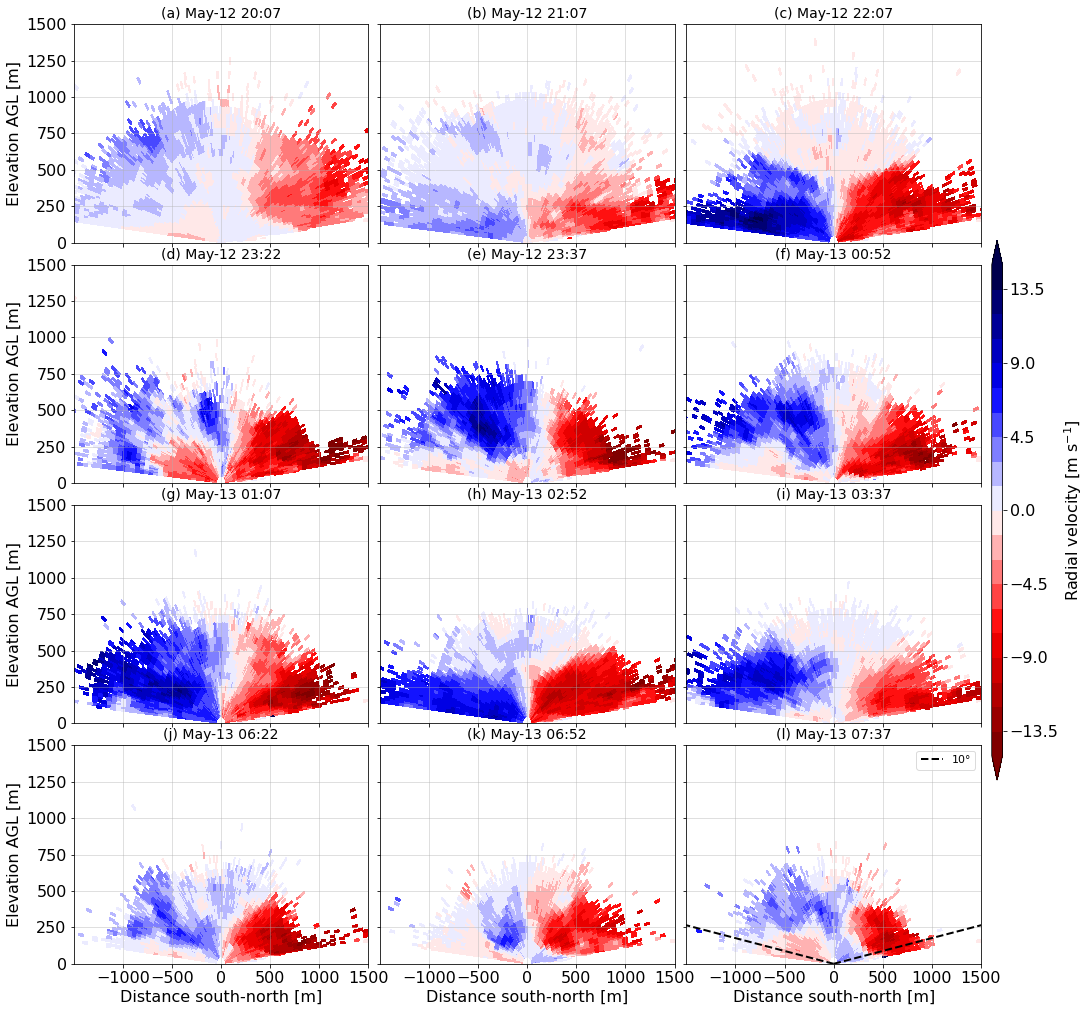

In [8]:
#### execute this part only for a selection of RHI's and in one plot
# run this cell first, it will create the rv arrays needed for the hovmoller diagram

import os
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from datetime import datetime, timedelta

# -----------------------------
# Parameters
# -----------------------------
CLims = [-15, 15]
n_levels = 20
levels = np.linspace(CLims[0], CLims[1], n_levels + 1)
# Create a BoundaryNorm for discrete color mapping
# tmap = plt.get_cmap('RdBu_r')
norm = mcolors.BoundaryNorm(boundaries=levels, ncolors=tmap.N)

path_WN = '/home/voyager-sbarc/SWEX2022_datasets/Lidars_ground/SBBG/v01/RHI/'

# -----------------------------
# Load .mat files
# -----------------------------
files = [f for f in os.listdir(path_WN) if f.startswith('RHI_0_202205') and f.endswith('.mat')]
files.sort()


# Flatten all scans
all_scans = []
for filename in files:
    mat = sio.loadmat(os.path.join(path_WN, filename), squeeze_me=True)
    rv_list = mat['rv']
    x_list = mat['x']
    y_list = mat['y']
    t_list = mat['t']
    for T in range(len(rv_list)):
        all_scans.append((x_list[T], y_list[T], rv_list[T], t_list[T]))

# Letters for subpanels
import string
panel_labels = list(string.ascii_lowercase)  # ['a', 'b', 'c', ...]        
        
# Indices of the scans you want
indices = [108,112,116, 
           121,122,127,
           128,135,138,
           149,151,154]
# Select only those scans
selected_scans = [all_scans[i] for i in indices]

# Figure layout
nrows, ncols = 4, 3
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 15), sharex=True, sharey=True)
axes = axes.flatten()

last_idx = len(selected_scans) - 1  # index 11 → panel (l)

max_range=2000

for idx, (X_raw, Y_raw, Z_raw, t_list) in enumerate(selected_scans):
    # Ensure t_list is iterable
    t_array = np.atleast_1d(t_list)

    tnumPDT = [datetime.fromordinal(int(tt) - 366) + timedelta(days=tt % 1) - timedelta(hours=7) 
               for tt in t_array]

    X = np.nan_to_num(np.array(X_raw, dtype=float), nan=0.0)
    Y = np.nan_to_num(np.array(Y_raw, dtype=float), nan=0.0)
    Z = np.ma.masked_invalid(np.array(Z_raw, dtype=float).T)
    
    ax = axes[idx]
    pc = ax.pcolormesh(X, Y, Z, cmap=tmap, norm=norm, shading='auto')

    # Left column elevation label
    if idx % ncols == 0:
        ax.set_ylabel('Elevation AGL [m]')
        # Set custom ticks, excluding -1500 and 1500
        ax.set_xticks([-1000, -500, 0, 500, 1000, 1500])
    else:
        ax.tick_params(labelleft=False)

    # Bottom row x-axis
    if idx // ncols == nrows - 1:
        ax.set_xlabel('Distance south-north [m]')
    else:
        ax.tick_params(labelbottom=False)

    # Subplot title with panel label
    panel_label = f"({panel_labels[idx]})"
    ax.set_title(f"{panel_label} {tnumPDT[0].strftime('%b-%d %H:%M')}", fontsize=14)
    
    ax.set_xlim([-1500, 1500])
    ax.set_ylim([0, 1500])
    ax.grid(True, alpha=0.5, zorder=0)


    # -------------------------------------------------
    # Draw elevation beam only on the last panel (l)
    # -------------------------------------------------
    if idx == last_idx:
        beam_styles = {10: '--'}
        beam_y_pos = np.linspace(0, max_range, 100)
        beam_y_neg = np.linspace(0, -max_range, 100)

        for ang, style in beam_styles.items():
            ang_rad = np.radians(ang)
            beam_z_pos = np.abs(beam_y_pos) * np.tan(ang_rad)
            beam_z_neg = np.abs(beam_y_neg) * np.tan(ang_rad)
            ax.plot(beam_y_pos, beam_z_pos, color='black', linewidth=2,
                    linestyle=style, zorder=7, label=f'{ang}°')
            ax.plot(beam_y_neg, beam_z_neg, color='black', linewidth=2,
                    linestyle=style, zorder=7)
        ax.legend(loc='upper right', fontsize=11, framealpha=0.7)


# Remove any empty axes
for j in range(idx + 1, nrows*ncols):
    fig.delaxes(axes[j])

# Single colorbar
cbar_ax = fig.add_axes([0.92, 0.25, 0.01, 0.5])
cbar = fig.colorbar(pc, cax=cbar_ax, extend='both')
cbar.set_label('Radial velocity [m s$^{-1}$]',labelpad=4)

# After plotting everything and before plt.show():
plt.subplots_adjust(left=0.07, right=0.91, top=0.95, bottom=0.08, hspace=0.1, wspace=0.04)

# plt.tight_layout(rect=[0, 0, 0.9, 1])

# plt.show()
figName = f"RHI_0_summary.png"
plt.savefig(figName, dpi=150)




In [9]:
# all plots are plotted here with the following script

import os
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from datetime import datetime, timedelta

# -----------------------------
# Parameters
# -----------------------------
CLims = [-15, 15]
n_levels = 20
levels = np.linspace(CLims[0], CLims[1], n_levels + 1)
# Create a BoundaryNorm for discrete color mapping
# tmap = plt.get_cmap('RdBu_r')
norm = mcolors.BoundaryNorm(boundaries=levels, ncolors=tmap.N)

path_WN = '/home/voyager-sbarc/SWEX2022_datasets/Lidars_ground/SBBG/v01/RHI/'

# -----------------------------
# Load .mat files
# -----------------------------
files = [f for f in os.listdir(path_WN) if f.startswith('RHI_0_202205') and f.endswith('.mat')]
files.sort()

# -----------------------------
# Loop through files
# -----------------------------
hovMolNorth = {hgt: [] for hgt in range(1, 26)}
hovMolSouth = {hgt: [] for hgt in range(1, 26)}
hovMolNorth_x = {hgt: [] for hgt in range(1, 26)}
hovMolSouth_x = {hgt: [] for hgt in range(1, 26)}
tnumPDTArray = []

for num, filename in enumerate(files[:8]):  # MATLAB 1:8 equivalent
    mat = sio.loadmat(os.path.join(path_WN, filename), squeeze_me=True)
    
    rv_list = mat['rv']  # list of 2D arrays
    x_list = mat['x']
    y_list = mat['y']
    t_list = mat['t']

    # Convert MATLAB datenum to Python datetime (subtract 7 hours for PDT)
    tnumPDT = [datetime.fromordinal(int(tt) - 366) + timedelta(days=tt%1) - timedelta(hours=7) for tt in t_list]

    for T in range(len(rv_list)):
        X = np.array(x_list[T], dtype=float)
        Y = np.array(y_list[T], dtype=float)
        Z = np.array(rv_list[T], dtype=float).T  # transpose to match MATLAB

        # Clean X and Y: replace NaNs with nearest neighbor or simple linear fill if needed
        # Here, just ensure finite values for pcolormesh
        if not np.all(np.isfinite(X)) or not np.all(np.isfinite(Y)):
            # Replace NaNs with nearest finite value along each axis
            X = np.nan_to_num(X, nan=0.0)
            Y = np.nan_to_num(Y, nan=0.0)
        
        # Mask invalid values
        Z = np.ma.masked_invalid(Z)

        # -----------------------------
        # RHI plot
        # -----------------------------
        plt.figure(figsize=(9,6))
        pc = plt.pcolormesh(X, Y, Z, cmap=tmap, norm=norm, shading='auto')
        cbar = plt.colorbar(pc, extend='both')

        # Draw elevation beams
        beam_styles = {10: '--', 6: ':', 3: '--'}
        beam_y_pos = np.linspace(0, 1500, 100)
        beam_y_neg = np.linspace(0, -1500, 100)
        
        for ang, style in beam_styles.items():
            ang_rad = np.radians(ang)
            beam_z_pos = np.abs(beam_y_pos) * np.tan(ang_rad)  # AGL so no lidar_terrain_height
            beam_z_neg = np.abs(beam_y_neg) * np.tan(ang_rad)
            plt.plot(beam_y_pos, beam_z_pos, color='black', linewidth=1.2, linestyle=style, zorder=7, label=f'{ang}°')
            plt.plot(beam_y_neg, beam_z_neg, color='black', linewidth=1.2, linestyle=style, zorder=7)
        
        plt.legend(loc='upper right', fontsize=9, framealpha=0.6)
        
        cbar.set_label('Radial velocity [m s$^{-1}$]')
        plt.xlabel('Distance south-north [m]')
        plt.ylabel('Elevation AGL [m]')
        plt.title(f"RHI {tnumPDT[T].strftime('%b-%d %H:%M')} PDT")
        plt.xlim([-1500, 1500])
        plt.ylim([0, 1500])
        plt.grid(True, alpha=0.5, zorder=0)
        plt.tight_layout()
        figName = f"SBBG_RHI_0_v2_{tnumPDT[T].strftime('%Y%m%d_%H%M')}_PDT.png"
        plt.savefig(figName, dpi=150)
        plt.close()

        # -----------------------------
        # Build Hovmöller data (north & south)
        # -----------------------------
        for hgt in range(1, 26):
            # North: take row hgt (along-beam) as-is
            hovMolNorth[hgt].append(Z[hgt, :])
            hovMolNorth_x[hgt].append(X[hgt, :])

            # South: take symmetric row from end
            hovMolSouth[hgt].append(Z[-hgt, :])
            hovMolSouth_x[hgt].append(X[-hgt, :])

        tnumPDTArray.append(tnumPDT[T])

# Convert lists to arrays for plotting
for hgt in range(1, 26):
    hovMolNorth[hgt] = np.array(hovMolNorth[hgt])
    hovMolSouth[hgt] = np.array(hovMolSouth[hgt])
    hovMolNorth_x[hgt] = np.array(hovMolNorth_x[hgt])
    hovMolSouth_x[hgt] = np.array(hovMolSouth_x[hgt])

tnumPDTArray = np.array(tnumPDTArray)



/tmp/ipykernel_1319481/414911201.py:67: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pc = plt.pcolormesh(X, Y, Z, cmap=tmap, norm=norm, shading='auto')
/tmp/ipykernel_1319481/414911201.py:67: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pc = plt.pcolormesh(X, Y, Z, cmap=tmap, norm=norm, shading='auto')
/tmp/ipykernel_1319481/414911201.py:67: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcol

In [10]:
# hovmoller part (to be run after cell above)

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np

IOPstart = datetime(2022,5,12,10,0)
IOPend = datetime(2022,5,13,10,0)
time_num = mdates.date2num(tnumPDTArray)

for hgt in range(1, 26):
    combined_x = np.hstack([hovMolSouth_x[hgt][0, :], hovMolNorth_x[hgt][0, :]])
    combined_data = np.hstack([hovMolSouth[hgt], hovMolNorth[hgt]])

    sort_idx = np.argsort(combined_x)
    combined_x_sorted = combined_x[sort_idx]
    combined_data_sorted = combined_data[:, sort_idx]

    col_idx = 22  
    height = Y[hgt, col_idx]
    distance = X[hgt, col_idx]
    angle_deg = np.degrees(np.arctan2(height, distance))

    fig, ax = plt.subplots(figsize=(8,6), constrained_layout=True)  # CONSTRAINED_LAYOUT

    pc = ax.pcolormesh(combined_x_sorted, time_num, combined_data_sorted,
                       cmap=tmap, norm=norm, shading='auto')

    # # Automatic colorbar
    cbar = fig.colorbar(pc, ax=ax, orientation='vertical', extend='both',
                        fraction=0.005, pad=0.02, shrink=0.6)
    cbar.set_label('Radial velocity [m s$^{-1}$]')

    
    ax.set_xlabel('Distance south-north [m]')
    ax.set_ylabel('Time [PDT]')
    ax.set_title(f'Hovmöller diagram — Elevation angle: {angle_deg:.1f}°')

    ax.xaxis.set_major_locator(plt.MaxNLocator(6))
    ax.yaxis_date()
    ax.yaxis.set_major_formatter(mdates.DateFormatter('%m/%d %H:%M'))

    ax.set_xlim([-2000, 2000])
    ax.set_ylim([mdates.date2num(IOPstart), mdates.date2num(IOPend)])
    ax.grid(True, alpha=0.5, zorder=0)

    figName = f"RHI_0_v2_hovmoller_south_north_hgt_{hgt}.png"
    plt.savefig(figName, dpi=150)
    plt.close()
